<div style="background:#080c10;border:1px solid #00d4ff;border-radius:10px;padding:26px 30px;">
<div style="color:#00d4ff;font-size:12px;letter-spacing:2px;font-weight:600;">OLIVIER SPORTS DATA · FROM CHICKEN AREA 🐔</div>
<div style="color:#ffffff;font-size:30px;font-weight:700;margin:10px 0 6px 0;">US Sports Master V2 — Verify Before You Buy</div>
<div style="color:#9fb3bf;font-size:15px;">227,081 games &amp; fights · 9 leagues · 1998 → 2 November 2026 · closing odds</div>
</div>

This notebook runs on the **full dataset**, the same nine CSV files delivered on Gumroad and Whop, not on the public sample.
Every table and chart below is computed live from those files, so you can check what you are buying:
coverage by league and season, data integrity, and the quality of the closing odds.

**Source:** OddsPortal. The odds are the average closing prices shown by the source, not attributable to any single bookmaker. UFC results are completed from the official UFC fight statistics and from our UFC Multi-Market dataset; the official statistics also give the event, location and per-fighter stats of 5,602 fights.

👉 [Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/ahlplc?utm_source=github&utm_medium=notebook&utm_campaign=us_sports_master) · also on [Whop](https://whop.com/oliviersportsdata/us-sports-master-historical-closing-odds-1998-2026/?utm_source=github&utm_medium=notebook&utm_campaign=us_sports_master)

**Contents**
1. Coverage by league
2. Integrity checks
3. Games per season
4. Are the closing odds calibrated?
5. Bookmaker margin over time
6. Favourites and home advantage
7. UFC
8. What you get

In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter, MaxNLocator
from IPython.display import display
warnings.filterwarnings("ignore")

# Signature colours: dark surface, one cyan accent, cool grey ink
BG, CYAN = "#080c10", "#00d4ff"
INK, INK2, MUTED = "#e8f1f5", "#9fb3bf", "#6b7d88"
GRID, AXIS, REF = "#16212b", "#2a3a46", "#56646e"

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "text.color": INK, "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})
THOUSANDS = FuncFormatter(lambda v, _: f"{v:,.0f}")


def show(df, caption=None):
    """Dark table in the notebook signature."""
    sty = df.style.set_table_styles([
        {"selector": "th", "props": [("background-color", "#0f1820"), ("color", CYAN), ("font-weight", "600"),
                                     ("border", "1px solid #1c2a35"), ("padding", "6px 10px"), ("text-align", "left")]},
        {"selector": "td", "props": [("background-color", BG), ("color", INK), ("border", "1px solid #1c2a35"),
                                     ("padding", "5px 10px"), ("text-align", "left")]},
        {"selector": "caption", "props": [("color", INK2), ("caption-side", "top"), ("text-align", "left"),
                                          ("padding", "4px 0 8px 0"), ("font-size", "13px")]},
    ]).hide(axis="index")
    if caption:
        sty = sty.set_caption(caption)
    display(sty)


def panel_grid(title, sharex=False, sharey=False, h=8.6):
    fig, axes = plt.subplots(3, 3, figsize=(13, h), sharex=sharex, sharey=sharey)
    fig.suptitle(title, x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    return fig, axes.ravel()

In [2]:
DATA_DIR = "/kaggle/input/datasets/oliviersportsdata/us-sports-master-closing-odds-v1"
LEAGUES = ["NFL", "NBA", "MLB", "NHL", "NCAAF", "NCAAB", "MLS", "WNBA", "UFC"]
TEAM = LEAGUES[:-1]
THREE_WAY = {"NHL", "MLS"}          # Home / Draw / Away, regulation time


def find_files():
    for root in (DATA_DIR, "/kaggle/input"):
        found = {}
        for f in sorted(glob.glob(os.path.join(root, "**", "*_Closing_Odds.csv"), recursive=True)):
            league = os.path.basename(f).split("_")[0]
            if league in LEAGUES and "SAMPLE" not in f.upper():
                found.setdefault(league, f)
        if len(found) == len(LEAGUES):
            return found
    raise FileNotFoundError(f"The nine *_Closing_Odds.csv files were not found under {DATA_DIR}")


def num(s):
    return pd.to_numeric(s.replace("", np.nan), errors="coerce")


def implied(american):
    """American odds -> implied probability (with the bookmaker margin still inside)."""
    a = np.asarray(american, dtype=float)
    dec = np.where(a > 0, 1 + a / 100, 1 + 100 / np.abs(a))
    return 1 / dec


FILES = find_files()
RAW = {k: pd.read_csv(FILES[k], encoding="utf-8-sig", dtype=str, keep_default_na=False) for k in LEAGUES}

G = {}                               # team leagues, typed
for k in TEAM:
    d = RAW[k].copy()
    for c in ["Home_Score", "Away_Score", "Total_Score", "Margin", "Home_Odds", "Draw_Odds", "Away_Odds", "Bookmakers"]:
        d[c] = num(d[c])
    d["Season_Start"] = d["Season"].str[:4].astype(int)
    d["ih"], d["id"], d["ia"] = implied(d["Home_Odds"]), implied(d["Draw_Odds"]), implied(d["Away_Odds"])
    G[k] = d

U = RAW["UFC"].copy()                # UFC, typed
STATS = [c for c in U.columns if c.startswith(("Fighter_1_", "Fighter_2_")) and not c.endswith("_Odds")]   # 8 per-fighter stats
for c in ["Fighter_1_Odds", "Fighter_2_Odds", "Round"] + STATS:
    U[c] = num(U[c])
U["Year"] = U["Year"].astype(int)
U["i1"], U["i2"] = implied(U["Fighter_1_Odds"]), implied(U["Fighter_2_Odds"])

print(f"{sum(len(d) for d in RAW.values()):,} rows loaded from {len(FILES)} files:")
for k in LEAGUES:
    print(f"  {k:6} {len(RAW[k]):>7,}  {os.path.basename(FILES[k])}")

227,081 rows loaded from 9 files:
  NFL      5,005  NFL_Closing_Odds.csv
  NBA     23,187  NBA_Closing_Odds.csv
  MLB     48,945  MLB_Closing_Odds.csv
  NHL     35,040  NHL_Closing_Odds.csv
  NCAAF   15,203  NCAAF_Closing_Odds.csv
  NCAAB   79,780  NCAAB_Closing_Odds.csv
  MLS      9,100  MLS_Closing_Odds.csv
  WNBA     4,225  WNBA_Closing_Odds.csv
  UFC      6,596  UFC_Closing_Odds.csv


## 1. Coverage by league

Rows, seasons and date range of each file. The total must match the **227,081** rows announced on the product page.
`Median books` is the median number of bookmakers in the closing average (the source stopped showing it in early March 2026, and from the 2019/2020 season in NCAAB).

In [3]:
rows = []
for k in LEAGUES:
    d = RAW[k]
    if k == "UFC":
        seasons, books = d["Year"], "–"
        with_odds = ((d["Fighter_1_Odds"] != "") & (d["Fighter_2_Odds"] != "")).mean()
    else:
        seasons, books = d["Season"], f"{G[k]['Bookmakers'].median():.0f}"
        with_odds = ((d["Home_Odds"] != "") & (d["Away_Odds"] != "")).mean()
    s = sorted(seasons.unique(), key=lambda x: x[:4])
    rows.append({"League": k, "Rows": f"{len(d):,}", "Seasons": f"{s[0]} → {s[-1]}", "Nb of seasons": len(s),
                 "First match": d["Date"].min(), "Last match": d["Date"].max(),
                 "Rows with closing odds": f"{with_odds:.1%}", "Median books": books})
total = sum(len(d) for d in RAW.values())
rows.append({"League": "TOTAL", "Rows": f"{total:,}", "Seasons": "", "Nb of seasons": "",
             "First match": min(RAW[k]["Date"].min() for k in LEAGUES),
             "Last match": max(RAW[k]["Date"].max() for k in LEAGUES),
             "Rows with closing odds": "", "Median books": ""})
show(pd.DataFrame(rows), "Coverage of the nine files")
print(("✔" if total == 227_081 else "✘") + f"  {total:,} rows (product page: 227,081)")

League,Rows,Seasons,Nb of seasons,First match,Last match,Rows with closing odds,Median books
NFL,"5,005",2008/2009 → 2026/2027,19,2008-09-05,2026-11-03,99.3%,8
NBA,"23,187",2008/2009 → 2026/2027,19,2008-10-29,2026-11-03,99.9%,8
MLB,"48,945",2006 → 2026,21,2006-05-15,2026-10-29,99.5%,3
NHL,"35,040",1998/1999 → 2026/2027,28,1998-10-09,2026-11-03,99.9%,3
NCAAF,"15,203",2008/2009 → 2026/2027,19,2008-10-17,2026-11-01,90.7%,7
NCAAB,"79,780",2008/2009 → 2026/2027,19,2008-11-20,2026-11-03,95.9%,5
MLS,"9,100",1998 → 2026,29,1998-03-21,2026-11-02,99.6%,3
WNBA,"4,225",2009 → 2026,18,2009-06-06,2026-11-01,99.9%,7
UFC,"6,596",2013 → 2026,13,2013-02-03,2026-11-01,86.1%,–
TOTAL,"227,081",,,1998-03-21,2026-11-03,,


✔  227,081 rows (product page: 227,081)


## 2. Integrity checks

Each check runs on **every row it applies to** (see *Values checked*). ✔ means no row fails it.

In [4]:
checks = []
def add(check, scope, n_checked, issues):
    checks.append({"Check": check, "Scope": scope, "Values checked": f"{n_checked:,}",
                   "Issues": f"{issues:,}", "Result": "✔" if issues == 0 else "✘"})

team_rows = sum(len(G[k]) for k in TEAM)
cols = {tuple(RAW[k].columns) for k in TEAM}
add("Same 18 columns, same order", "8 team files", 8, 0 if len(cols) == 1 and len(next(iter(cols))) == 18 else 1)

bad = sum((~RAW[k]["Date"].str.fullmatch(r"\d{4}-\d{2}-\d{2}") | pd.to_datetime(RAW[k]["Date"], errors="coerce").isna()).sum()
          for k in LEAGUES)
add("Date is a valid ISO 8601 date (YYYY-MM-DD)", "all files", total, int(bad))

bad = sum((~RAW[k]["Time"].str.fullmatch(r"(?:[01]\d|2[0-3]):[0-5]\d") & (RAW[k]["Time"] != "")).sum() for k in LEAGUES)
add("Time is HH:MM when present", "all files", total, int(bad))

bad = 0
for k in TEAM:
    d = G[k]
    year = d["Date"].str[:4].astype(int)
    two_years = d["Season"].str.contains("/")
    bad += int(((two_years & (year != d["Season_Start"]) & (year != d["Season_Start"] + 1))
                | (~two_years & (year != d["Season_Start"]))).sum())
add("Date falls inside its season", "8 team files", team_rows, bad)

bad = n = 0
for k in TEAM:
    d = G[k]
    w = np.select([d["Home_Score"] > d["Away_Score"], d["Home_Score"] < d["Away_Score"],
                   d["Home_Score"] == d["Away_Score"]], ["Home", "Away", "Draw"], default="")
    bad += int((w != d["Winner"]).sum()); n += len(d)
add("Winner matches the final score", "8 team files", n, bad)

bad = n = 0
for k in TEAM:
    d = G[k].dropna(subset=["Home_Score", "Away_Score"])
    bad += int(((d["Home_Score"] + d["Away_Score"] != d["Total_Score"])
                | ((d["Home_Score"] - d["Away_Score"]).abs() != d["Margin"])).sum()); n += len(d)
add("Total_Score and Margin match the scores", "8 team files", n, bad)

vals = pd.concat([G[k][c] for k in TEAM for c in ("Home_Odds", "Draw_Odds", "Away_Odds")]
                 + [U["Fighter_1_Odds"], U["Fighter_2_Odds"]]).dropna()
add("Odds are valid American prices (≤ −100 or ≥ +100)", "all files", len(vals), int((vals.abs() < 100).sum()))

n_priced = bad = 0
for k in TEAM:
    d = G[k].dropna(subset=["ih", "ia"] + (["id"] if k in THREE_WAY else []))
    s_ = d["ih"] + d["ia"] + (d["id"] if k in THREE_WAY else 0)
    n_priced += len(d); bad += int((s_ < 1).sum())
d = U.dropna(subset=["i1", "i2"])
n_priced += len(d); bad += int((d["i1"] + d["i2"] < 1).sum())
add("Closing prices are consistent (implied probabilities sum to 100 % or more)", "all files", n_priced, bad)

add("Draw_Odds only in three-way leagues (NHL, MLS)", "8 team files", team_rows,
    int(sum(G[k]["Draw_Odds"].notna().sum() for k in TEAM if k not in THREE_WAY)))

add("No exact duplicate row", "all files", total, int(sum(RAW[k].duplicated().sum() for k in LEAGUES)))
add("No game listed twice (same date, time, teams and score)", "8 team files", team_rows,
    int(sum(RAW[k].duplicated(["Date", "Time", "Home_Team", "Away_Team", "Home_Score", "Away_Score"]).sum() for k in TEAM)))

win = U[U["Outcome"] == "Win"]
add("UFC: Winner is one of the two fighters", "UFC", len(win),
    int((~((win["Winner"] == win["Fighter_1"]) | (win["Winner"] == win["Fighter_2"]))).sum()))
METHODS = {"KO", "TKO", "KO/TKO", "SUB", "DEC", "DQ", "Not specified"}
is_win = U["Outcome"] == "Win"
add("UFC: Method on wins only: KO, TKO, KO/TKO, SUB, DEC, DQ or Not specified", "UFC", len(U),
    int((is_win & ~U["Method"].isin(METHODS)).sum() + (~is_win & (U["Method"] != "")).sum()))
r = U[U["Round"].notna()]
add("UFC: Round 1 to 5, Finish_Time M:SS when given", "UFC", len(r),
    int((~r["Round"].between(1, 5)).sum() + (~r["Finish_Time"].str.fullmatch(r"[0-5]?\d:[0-5]\d") & (r["Finish_Time"] != "")).sum()))
st = U.loc[U["Event"] != "", STATS]
add("UFC: per-fighter stats are whole numbers", "UFC", st.size,
    int(st.isna().sum().sum() + (st.fillna(0) % 1 != 0).sum().sum()))

show(pd.DataFrame(checks), "Integrity checks")
missing_time = {k: int((RAW[k]["Time"] == "").sum()) for k in LEAGUES if (RAW[k]["Time"] == "").any()}
print(f"Note: Time is empty on {sum(missing_time.values())} row(s) out of {total:,} {missing_time}.")

Check,Scope,Values checked,Issues,Result
"Same 18 columns, same order",8 team files,8,0,✔
Date is a valid ISO 8601 date (YYYY-MM-DD),all files,"227,081",0,✔
Time is HH:MM when present,all files,"227,081",0,✔
Date falls inside its season,8 team files,"220,485",0,✔
Winner matches the final score,8 team files,"220,485",0,✔
Total_Score and Margin match the scores,8 team files,"219,943",0,✔
Odds are valid American prices (≤ −100 or ≥ +100),all files,"487,076",0,✔
Closing prices are consistent (implied probabilities sum to 100 % or more),all files,"221,130",0,✔
"Draw_Odds only in three-way leagues (NHL, MLS)",8 team files,"220,485",0,✔
No exact duplicate row,all files,"227,081",0,✔


Note: Time is empty on 515 row(s) out of 227,081 {'MLB': 2, 'NCAAF': 5, 'NCAAB': 6, 'MLS': 15, 'UFC': 487}.


## 3. Games per season

One panel per league, one bar per season (season start year). The first and last seasons can be partial:
each league starts when the source starts and stops with the games of 2 November 2026 (North American time).
Shortened seasons show up as dips (NHL 2012/2013 lockout, MLB 2020 and the 2019/2020 – 2020/2021 pandemic seasons).
There was no NHL season in 2004/2005 (lockout).

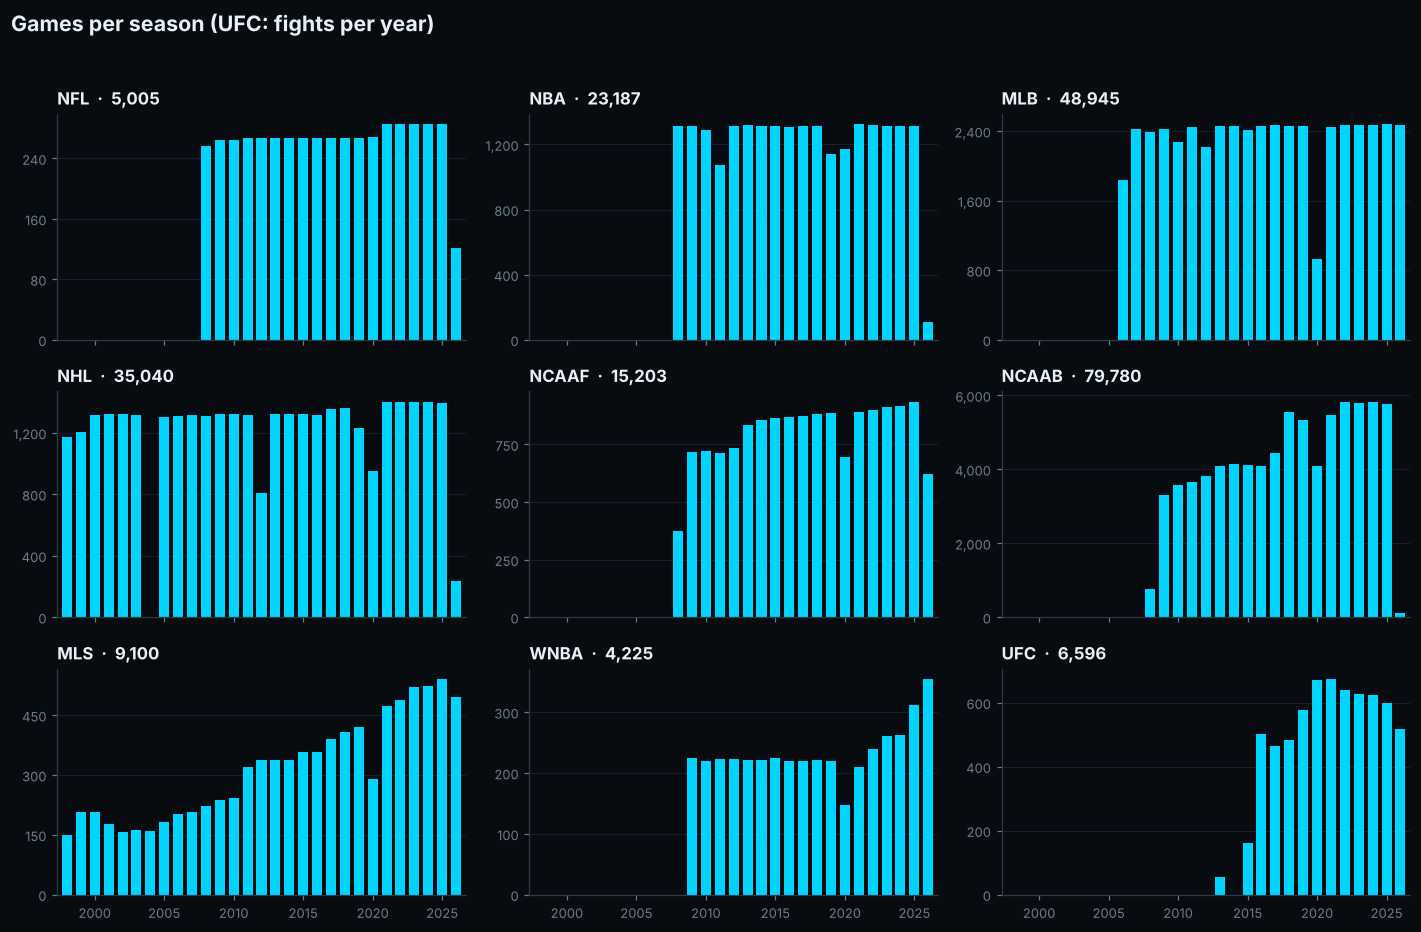

Season start,NFL,NBA,MLB,NHL,NCAAF,NCAAB,MLS,WNBA,UFC
1998,,,,"1,170",,,150,,
1999,,,,"1,203",,,206,,
2000,,,,"1,315",,,206,,
2001,,,,"1,320",,,176,,
2002,,,,"1,319",,,157,,
2003,,,,"1,317",,,161,,
2004,,,,,,,159,,
2005,,,,"1,300",,,181,,
2006,,,"1,842","1,307",,,203,,
2007,,,"2,422","1,315",,,206,,


In [5]:
fig, axes = panel_grid("Games per season (UFC: fights per year)", sharex=True)
pivot = {}
for ax, k in zip(axes, LEAGUES):
    c = (U.groupby("Year").size() if k == "UFC" else G[k].groupby("Season_Start").size())
    pivot[k] = c
    ax.bar(c.index, c.values, width=0.72, color=CYAN, linewidth=0)
    ax.set_title(f"{k}  ·  {c.sum():,}")
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.set_xlim(1997.3, 2026.7)
    ax.grid(axis="x", visible=False)
for ax in axes[6:]:
    ax.set_xticks(range(2000, 2027, 5))
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

table_ps = pd.DataFrame(pivot).sort_index()
table_ps.index.name = "Season start"
show(table_ps.apply(lambda col: col.map(lambda v: "" if pd.isna(v) else f"{int(v):,}")).reset_index(),
     "Rows per season (season start year)")

## 4. Are the closing odds calibrated?

If the closing prices are genuine, a side priced at 70 % should win about 70 % of the time.
The odds are converted to probabilities with the bookmaker margin removed, grouped in 5-point bins,
and compared with how often that side actually won. Points on the grey diagonal mean well-calibrated prices.

* Two-way leagues: probability of a home win (ties excluded).
* NHL and MLS (three-way market, regulation time): probability of a home win in regulation time.
* UFC: probability of a Fighter_1 win (fights with a winner).

`Error` is the gap between priced and observed frequency, averaged over all games, in percentage points.

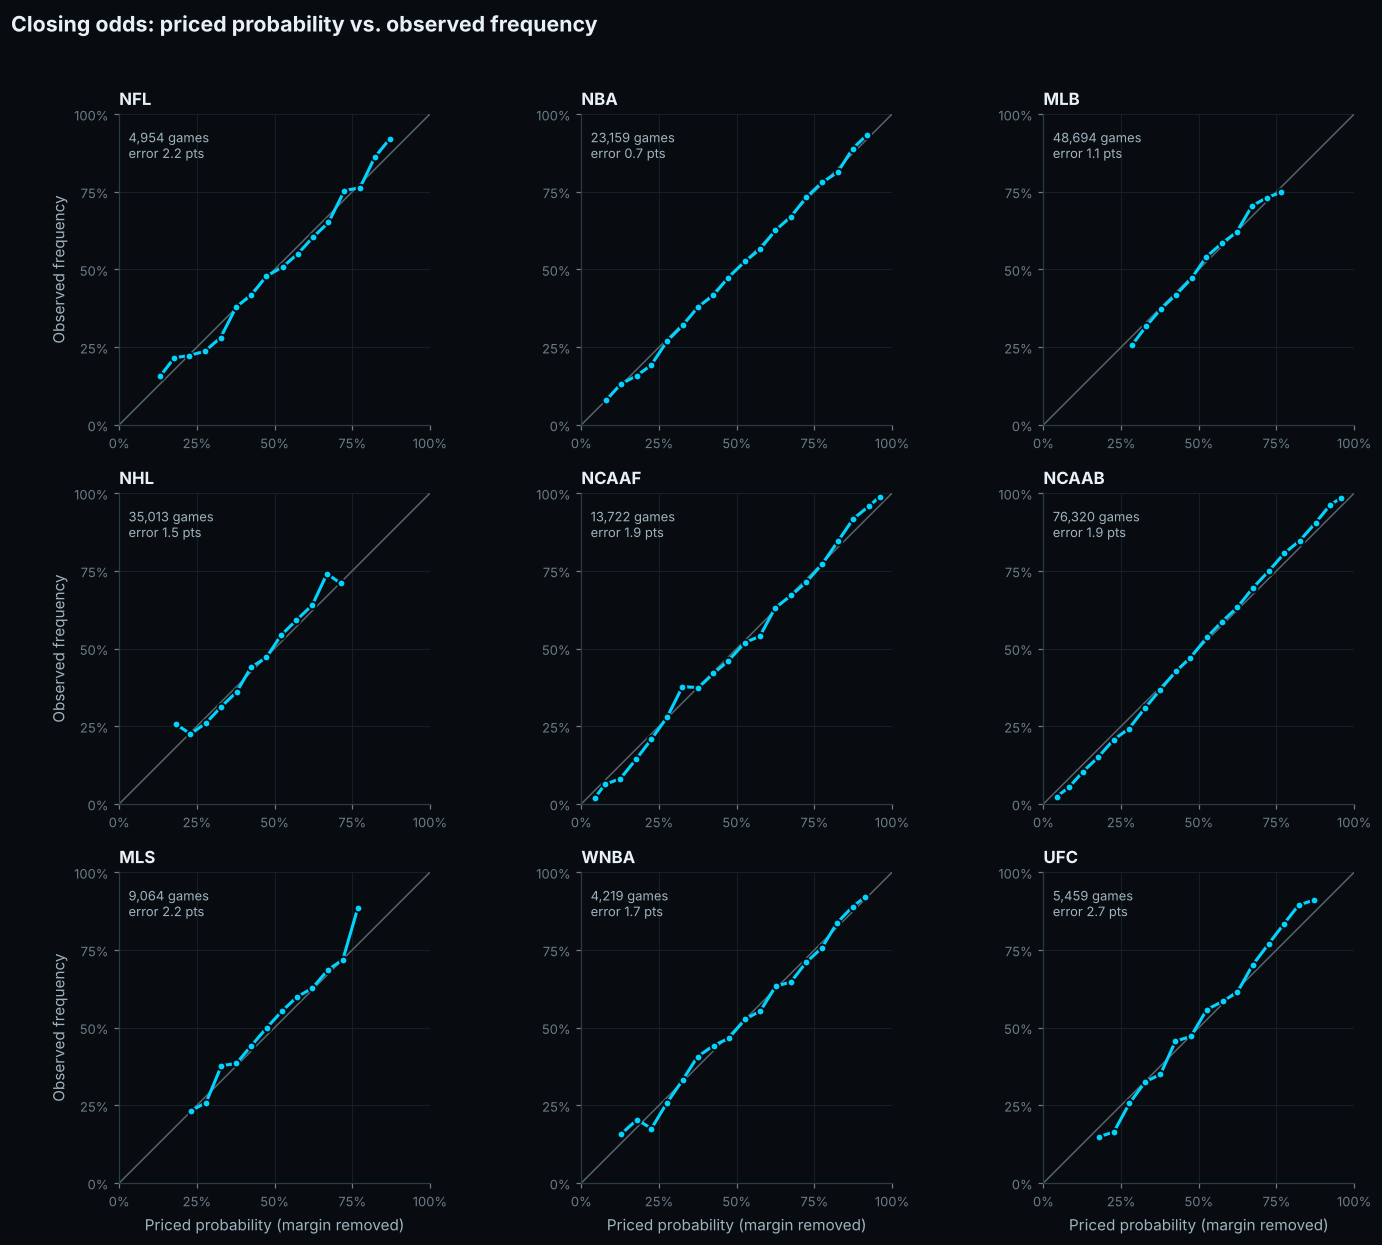

League,Games used,Priced (mean),Observed,Error (pts),Brier score
NFL,"4,954",56.4%,55.8%,2.2,0.211
NBA,"23,159",58.0%,57.8%,0.7,0.202
MLB,"48,694",53.1%,53.7%,1.1,0.241
NHL,"35,013",42.6%,42.7%,1.5,0.236
NCAAF,"13,722",58.6%,59.0%,1.9,0.169
NCAAB,"76,320",62.0%,63.2%,1.9,0.179
MLS,"9,064",46.7%,48.7%,2.2,0.240
WNBA,"4,219",57.8%,57.4%,1.7,0.204
UFC,"5,459",54.7%,56.1%,2.7,0.209


In [6]:
def calibration_data(k):
    """(probability, outcome 0/1) for one league."""
    if k == "UFC":
        d = U[(U["Outcome"] == "Win") & U["i1"].notna() & U["i2"].notna()]
        return (d["i1"] / (d["i1"] + d["i2"])).values, (d["Winner"] == d["Fighter_1"]).astype(int).values
    d = G[k].dropna(subset=["ih", "ia", "Home_Score"])
    if k in THREE_WAY:
        d = d.dropna(subset=["id"])
        p = d["ih"] / (d["ih"] + d["id"] + d["ia"])
        y = (d["Winner"] == "Home") & (d["Match_Ending"] == "Regular Time")
    else:
        d = d[d["Winner"] != "Draw"]
        p = d["ih"] / (d["ih"] + d["ia"])
        y = d["Winner"] == "Home"
    return p.values, y.astype(int).values


def bins(p, y, width=0.05):
    b = np.clip((p / width).astype(int), 0, int(round(1 / width)) - 1)
    t = pd.DataFrame({"b": b, "p": p, "y": y}).groupby("b").agg(n=("y", "size"), p=("p", "mean"), y=("y", "mean"))
    return t


fig, axes = panel_grid("Closing odds: priced probability vs. observed frequency", h=11.5)
summary = []
for ax, k in zip(axes, LEAGUES):
    p, y = calibration_data(k)
    t = bins(p, y)
    err = float((t["n"] * (t["p"] - t["y"]).abs()).sum() / t["n"].sum())
    shown = t[t["n"] >= 25]
    ax.plot([0, 1], [0, 1], color=REF, linewidth=1)
    ax.plot(shown["p"], shown["y"], color=CYAN, linewidth=2, marker="o", markersize=5,
            markeredgecolor=BG, markeredgewidth=1.2)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xticks([0, .25, .5, .75, 1]); ax.set_yticks([0, .25, .5, .75, 1])
    ax.set_title(k)
    ax.text(0.03, 0.95, f"{len(p):,} games\nerror {100 * err:.1f} pts", transform=ax.transAxes,
            va="top", fontsize=8.5, color=INK2)
    summary.append({"League": k, "Games used": f"{len(p):,}",
                    "Priced (mean)": f"{p.mean():.1%}", "Observed": f"{y.mean():.1%}",
                    "Error (pts)": f"{100 * err:.1f}", "Brier score": f"{np.mean((p - y) ** 2):.3f}"})
for ax in axes[6:]:
    ax.set_xlabel("Priced probability (margin removed)")
for ax in axes[::3]:
    ax.set_ylabel("Observed frequency")
fig.tight_layout(rect=(0, 0, 1, 0.965))
plt.show()
show(pd.DataFrame(summary), "Calibration summary (home side; Fighter_1 for UFC)")

## 5. Bookmaker margin over time

Margin (overround) = sum of the implied probabilities of all outcomes − 1, on the closing odds; median per season.
Two outcomes for the two-way leagues and UFC, three for NHL and MLS.

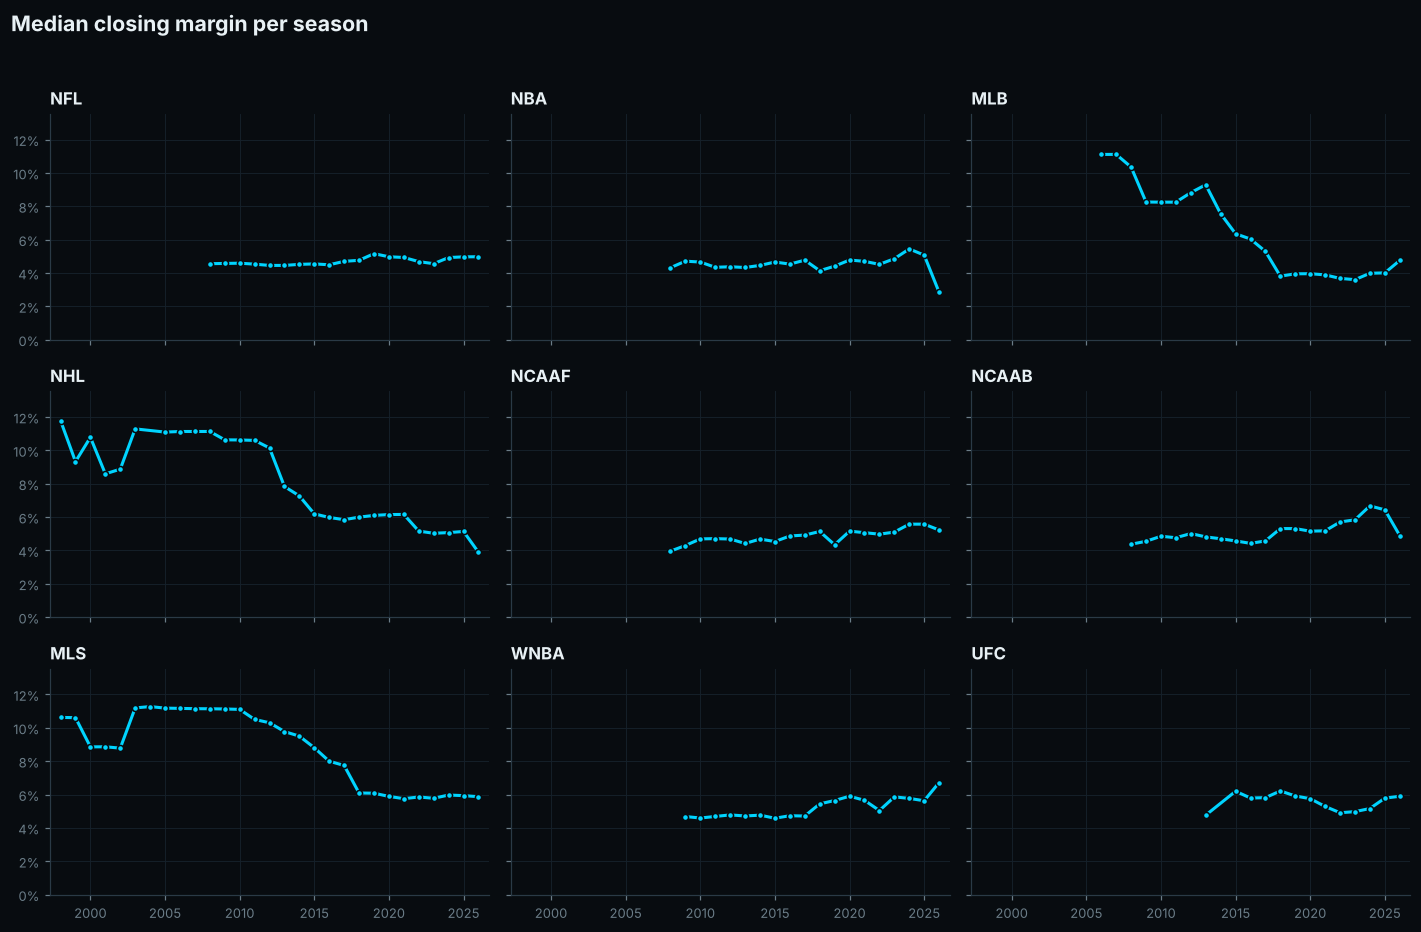

League,First season,Median margin then,Last season,Median margin now,Rows with a negative margin
NFL,2008,4.6%,2026,5.0%,0
NBA,2008,4.3%,2026,2.8%,0
MLB,2006,11.1%,2026,4.8%,0
NHL,1998,11.8%,2026,3.9%,0
NCAAF,2008,4.0%,2026,5.2%,0
NCAAB,2008,4.4%,2026,4.9%,0
MLS,1998,10.6%,2026,5.9%,0
WNBA,2009,4.7%,2026,6.7%,0
UFC,2013,4.8%,2026,5.9%,0


In [7]:
def margins(k):
    if k == "UFC":
        d = U.dropna(subset=["i1", "i2"])
        return pd.Series((d["i1"] + d["i2"] - 1).values, index=d["Year"].values)
    d = G[k].dropna(subset=["ih", "ia"] + (["id"] if k in THREE_WAY else []))
    m = d["ih"] + d["ia"] - 1 + (d["id"] if k in THREE_WAY else 0)
    return pd.Series(m.values, index=d["Season_Start"].values)


fig, axes = panel_grid("Median closing margin per season", sharex=True, sharey=True)
mrows = []
M = {k: margins(k) for k in LEAGUES}
top = max(float(M[k].groupby(level=0).median().max()) for k in LEAGUES)
for ax, k in zip(axes, LEAGUES):
    m = M[k]
    med = m.groupby(level=0).median()
    ax.plot(med.index, med.values, color=CYAN, linewidth=2, marker="o", markersize=4,
            markeredgecolor=BG, markeredgewidth=1)
    ax.set_title(k)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(1997.3, 2026.7)
    ax.set_ylim(0, top * 1.15)
    mrows.append({"League": k, "First season": int(med.index[0]), "Median margin then": f"{med.iloc[0]:.1%}",
                  "Last season": int(med.index[-1]), "Median margin now": f"{med.iloc[-1]:.1%}",
                  "Rows with a negative margin": f"{int((m < 0).sum()):,}"})
for ax in axes[6:]:
    ax.set_xticks(range(2000, 2027, 5))
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()
show(pd.DataFrame(mrows), "Closing margin, first vs. last season")

## 6. Favourites and home advantage

The closing favourite is the side with the higher priced probability (margin removed).
The bar is how often it actually won; the white tick is how often the odds said it would.
For NHL and MLS the market is regulation time, so a favourite counts as a winner only in regulation.

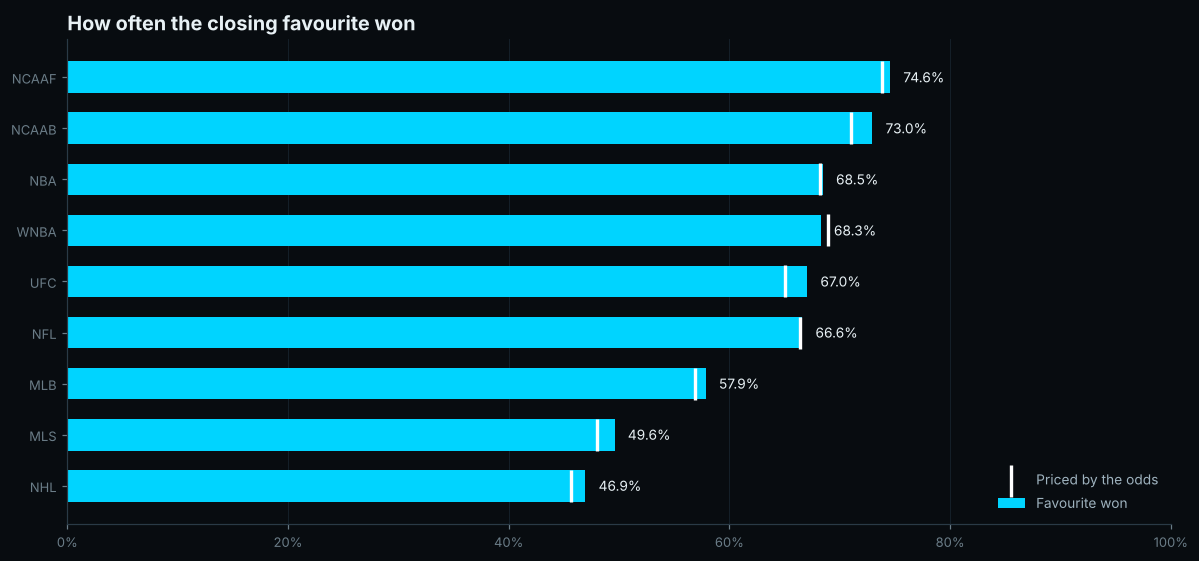

League,Games,Favourite won,Priced,Home won (final result)
NFL,"4,946",66.6%,66.4%,55.6%
NBA,"23,119",68.5%,68.2%,57.8%
MLB,"48,069",57.9%,56.8%,53.7%
NHL,"34,626",46.9%,45.6%,53.2%
NCAAF,"13,710",74.6%,73.9%,59.0%
NCAAB,"76,183",73.0%,71.0%,63.2%
MLS,"9,005",49.6%,48.0%,50.1%
WNBA,"4,217",68.3%,68.9%,57.4%
UFC,"5,441",67.0%,65.1%,–


In [8]:
frows = []
for k in LEAGUES:
    if k == "UFC":
        d = U[(U["Outcome"] == "Win") & U["i1"].notna() & U["i2"].notna()]
        p1 = d["i1"] / (d["i1"] + d["i2"])
        d = d[p1 != 0.5]; p1 = p1[p1 != 0.5]
        fav_p = np.maximum(p1, 1 - p1)
        fav_won = np.where(p1 > 0.5, d["Winner"] == d["Fighter_1"], d["Winner"] == d["Fighter_2"])
        home = np.nan
    else:
        d = G[k].dropna(subset=["ih", "ia", "Home_Score"] + (["id"] if k in THREE_WAY else []))
        home = (d["Winner"] == "Home").mean()
        if k in THREE_WAY:
            s = d["ih"] + d["id"] + d["ia"]
            ph, pa = d["ih"] / s, d["ia"] / s
            reg = d["Match_Ending"] == "Regular Time"
            won_h, won_a = (d["Winner"] == "Home") & reg, (d["Winner"] == "Away") & reg
        else:
            d = d[d["Winner"] != "Draw"]
            ph = d["ih"] / (d["ih"] + d["ia"]); pa = 1 - ph
            won_h, won_a = d["Winner"] == "Home", d["Winner"] == "Away"
        keep = ph != pa
        ph, pa, won_h, won_a = ph[keep], pa[keep], won_h[keep], won_a[keep]
        fav_p = np.maximum(ph, pa)
        fav_won = np.where(ph > pa, won_h, won_a)
    frows.append({"League": k, "Games": len(fav_p), "Favourite won": float(np.mean(fav_won)),
                  "Priced": float(np.mean(fav_p)), "Home won": home})
fav = pd.DataFrame(frows).sort_values("Favourite won")

fig, ax = plt.subplots(figsize=(11, 5.2))
y = np.arange(len(fav))
ax.barh(y, fav["Favourite won"], height=0.62, color=CYAN, linewidth=0, label="Favourite won")
ax.scatter(fav["Priced"], y, marker="|", s=420, linewidths=2.2, color="#ffffff", zorder=3, label="Priced by the odds")
for yi, v in zip(y, fav["Favourite won"]):
    ax.text(v + 0.012, yi, f"{v:.1%}", va="center", fontsize=9, color=INK)
ax.set_yticks(y, fav["League"])
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title("How often the closing favourite won", fontsize=13)
ax.legend(loc="lower right", fontsize=9, labelcolor=INK2)
fig.tight_layout()
plt.show()

out = fav.sort_values("League", key=lambda s: s.map(LEAGUES.index)).copy()
out["Games"] = out["Games"].map("{:,}".format)
for c in ["Favourite won", "Priced", "Home won"]:
    out[c] = out[c].map(lambda v: "–" if pd.isna(v) else f"{v:.1%}")
show(out.rename(columns={"Home won": "Home won (final result)"}), "Favourites and home advantage")

## 7. UFC

One row per fight, 29 columns: organisation, weight class, gender, event and location, both fighters, status, outcome, winner,
method (`KO`, `TKO`, `KO/TKO`, `SUB`, `DEC` or `DQ`; `Not specified` for 6 wins whose result was changed after the event)
and its detail, round and finish time, per-fighter stats (knockdowns,
significant strikes landed, takedowns landed, submission attempts), comment and the closing odds of each fighter.
Cancelled fights and fights without a result are kept and labelled (`Outcome`), never dropped silently.
The official UFC statistics do not separate knockouts from technical knockouts: `KO/TKO` is used when only they give the method.


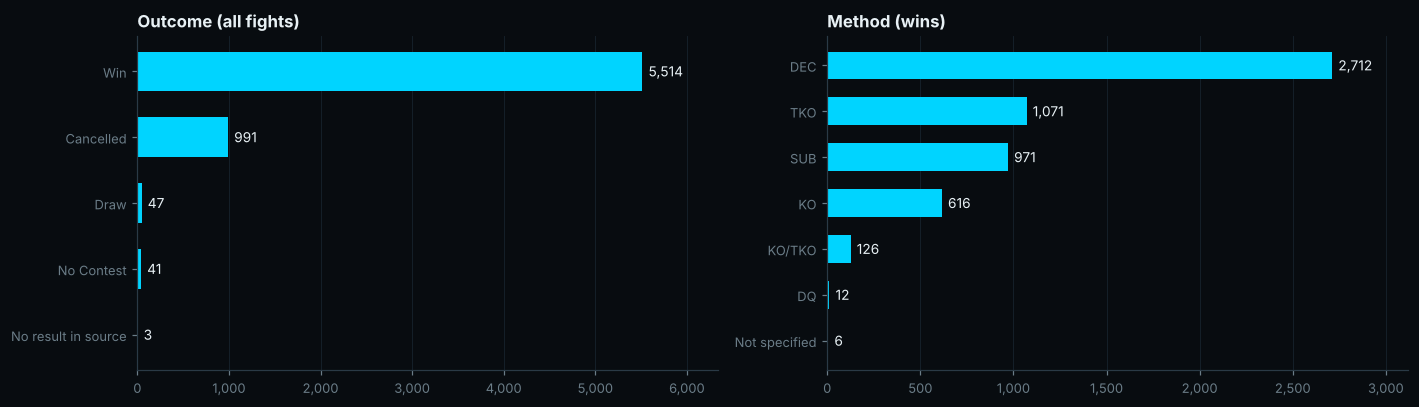

Year,Fights,Wins,Cancelled,No result in source,With stats,Favourite won
2013,56,56,0,0,56,71.9%
2015,160,152,4,0,156,62.5%
2016,501,465,27,0,474,64.5%
2017,466,438,19,0,447,68.3%
2018,484,469,12,0,472,65.6%
2019,577,507,62,0,515,62.7%
2020,672,447,217,0,455,66.2%
2021,673,480,182,0,491,64.9%
2022,638,499,135,0,503,68.1%
2023,626,502,108,0,518,67.6%


5,602 fights with event, location and the 8 per-fighter stats


In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, s, title in [(a1, U["Outcome"].value_counts(), "Outcome (all fights)"),
                     (a2, U.loc[U["Outcome"] == "Win", "Method"].value_counts(), "Method (wins)")]:
    s = s.sort_values()
    ax.barh(s.index, s.values, height=0.6, color=CYAN, linewidth=0)
    for i, v in enumerate(s.values):
        ax.text(v + s.max() * 0.012, i, f"{v:,}", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, s.max() * 1.15)
    ax.xaxis.set_major_formatter(THOUSANDS)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
fig.tight_layout()
plt.show()

w = U[(U["Outcome"] == "Win") & U["i1"].notna() & U["i2"].notna()].copy()
w["fav1"] = w["i1"] > w["i2"]
w = w[w["i1"] != w["i2"]]
w["fav_won"] = np.where(w["fav1"], w["Winner"] == w["Fighter_1"], w["Winner"] == w["Fighter_2"])
by_year = U.groupby("Year").agg(Fights=("Outcome", "size"),
                                Wins=("Outcome", lambda s: int((s == "Win").sum())),
                                Cancelled=("Outcome", lambda s: int((s == "Cancelled").sum())),
                                No_result=("Outcome", lambda s: int((s == "No result in source").sum())),
                                With_stats=("Event", lambda s: int((s != "").sum())))
by_year["Favourite won"] = w.groupby("Year")["fav_won"].mean().map(lambda v: f"{v:.1%}")
show(by_year.rename(columns={"No_result": "No result in source", "With_stats": "With stats"}).reset_index(), "UFC by year")
print(f"{int((U['Event'] != '').sum()):,} fights with event, location and the 8 per-fighter stats")

## 8. What you get

* **9 CSV files in 1 ZIP** (one per league) + `README.md`
* **227,081 rows**: 220,485 team-sport games (NFL, NBA, MLB, NHL, NCAAF, NCAAB, MLS, WNBA) and 6,596 UFC fights, **1998 → 2 November 2026**
* Closing moneyline odds (two-way) and three-way odds (NHL regulation time, MLS), American format
* Scores, winner, total, margin, how the game ended (overtime, shootout, extra time, penalties…) and stage (regular season, playoffs, Wild Card, bowls, NBA play-in…)
* UFC: 29 columns, with event and location, detailed method, round and finish time, and per-fighter stats for 5,602 fights
* UTF-8 with BOM, comma-separated, ISO dates, Central European Time (early seasons: see the README), home team first: `pd.read_csv()` ready
* Not included: preseason games, All-Star games, ONE Championship fights
* Coverage follows the source, which misses some games: MLB 2006 starts on 15 May 2006 and NCAAF 2008/2009 on 17 October 2008; there are no games from 4 to 14 September 2010 and from 7 to 22 May 2012 in MLB, from 4 July to 28 August 1998 in MLS, and from 28 November to 18 December 2008 in NCAAB (Paris dates). Around fifty MLB games of 2018–2022 and 63 UFC fights of 2016–2026 are also missing (details in the README)
* `Bookmakers` and `Final_Result_Only` are filled up to early March 2026 (`Final_Result_Only`: 23 March in NCAAB) and empty for later games, as the source no longer shows them. Also empty: `Bookmakers` in NCAAB from 2019/2020, and `Final_Result_Only` for the 487 UFC fights added in V2 (details in the README)
* Inconsistent source prices (NFL and NCAAF 2008/2009, a few isolated games and fights) were corrected or left empty: 597 games and 1 UFC fight, details in the README

**Source:** OddsPortal. The odds are the average closing prices shown by the source, not attributable to any single bookmaker.

👉 [Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/ahlplc?utm_source=github&utm_medium=notebook&utm_campaign=us_sports_master) · also on [Whop](https://whop.com/oliviersportsdata/us-sports-master-historical-closing-odds-1998-2026/?utm_source=github&utm_medium=notebook&utm_campaign=us_sports_master)

New games every month: [US Sports Master monthly updates](https://sportsdataolivier.gumroad.com/l/mudppx?utm_source=github&utm_medium=notebook&utm_campaign=us_sports_master) (subscription, cancel anytime)

*Olivier Sports Data — From Chicken Area 🐔*
